# RideSafe — Pothole Detection Using Deep Learning

## 1. Project Overview

RideSafe is a deep learning-based pothole detection system that classifies road images into two categories:

- Pothole
- No Pothole

The project uses a custom Residual Convolutional Neural Network (CNN) trained from scratch using PyTorch.

### Project Objectives

1. Prepare and explore the road image dataset.
2. Develop a custom CNN architecture using residual connections.
3. Train the model using PyTorch.
4. Evaluate the trained model on unseen test data.
5. Predict potholes in individual road images.

### Technologies Used

- Python
- PyTorch
- Torchvision
- NumPy
- Matplotlib
- Scikit-learn
- Pillow

## 2. Environment Setup

Import the libraries required for data exploration, visualization, model execution, and evaluation.

The project uses PyTorch for deep learning and Scikit-learn for evaluation metrics.

In [34]:
import os
import sys
import json
import random
import subprocess

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torchvision

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)

print("Python version:", sys.version)
print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("NumPy version:", np.__version__)

Python version: 3.12.1 (tags/v3.12.1:2305ca5, Dec  7 2023, 22:03:25) [MSC v.1937 64 bit (AMD64)]
PyTorch version: 2.15.0+cpu
Torchvision version: 0.29.2+cpu
NumPy version: 2.5.4


## 3. Project Configuration

Define the root directory of the project and the paths to the dataset, model checkpoints, and results.

The notebook uses the same directory structure as the original Python implementation.

In [35]:
ROOT = Path.cwd()

DATA_DIR = ROOT / "data"
SRC_DIR = ROOT / "src"
MODELS_DIR = ROOT / "models"
RESULTS_DIR = ROOT / "results"

print("Project root:", ROOT)
print("Dataset directory:", DATA_DIR)
print("Source directory:", SRC_DIR)
print("Models directory:", MODELS_DIR)
print("Results directory:", RESULTS_DIR)

Project root: D:\RideSafe\pothole-detection
Dataset directory: D:\RideSafe\pothole-detection\data
Source directory: D:\RideSafe\pothole-detection\src
Models directory: D:\RideSafe\pothole-detection\models
Results directory: D:\RideSafe\pothole-detection\results


In [36]:
# Verify that the important project files exist

required_files = [
    SRC_DIR / "dataset.py",
    SRC_DIR / "model.py",
    SRC_DIR / "train.py",
    SRC_DIR / "evaluate.py",
    SRC_DIR / "predict.py",
]

for file in required_files:
    print(file.name, ":", "Found" if file.exists() else "MISSING")

assert DATA_DIR.exists(), "Dataset directory not found!"
assert SRC_DIR.exists(), "Source directory not found!"
assert all(file.exists() for file in required_files), "One or more source files are missing!"

dataset.py : Found
model.py : Found
train.py : Found
evaluate.py : Found
predict.py : Found


## 4. Dataset Exploration

The dataset contains two classes:

1. No Pothole
2. Pothole

Before training, we examine the dataset distribution and visualize a few sample images.

This helps us understand the dataset and identify potential class imbalance.

In [38]:
CLASSES = ["no_pothole", "pothole"]

class_counts = {}

for class_name in CLASSES:
    class_folder = DATA_DIR / class_name

    images = list(class_folder.glob("*.jpg"))
    class_counts[class_name] = len(images)

print("Dataset Distribution")

for class_name, count in class_counts.items():
    print(f"{class_name}: {count} images")

print("Total images:", sum(class_counts.values()))

Dataset Distribution
no_pothole: 1671 images
pothole: 564 images
Total images: 2235


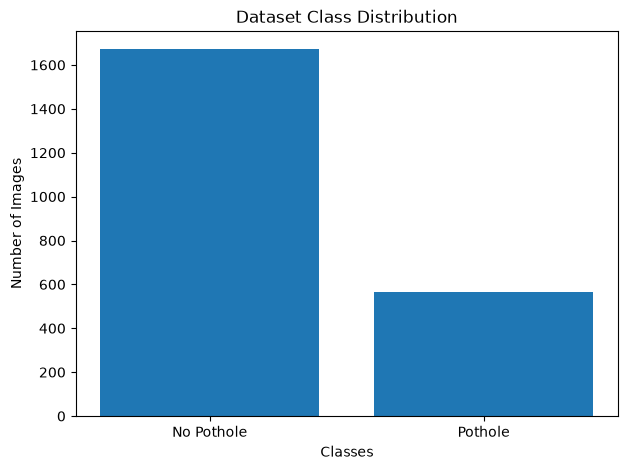

In [39]:
plt.figure(figsize=(7, 5))

plt.bar(
    ["No Pothole", "Pothole"],
    [class_counts["no_pothole"], class_counts["pothole"]]
)

plt.title("Dataset Class Distribution")
plt.xlabel("Classes")
plt.ylabel("Number of Images")

plt.show()

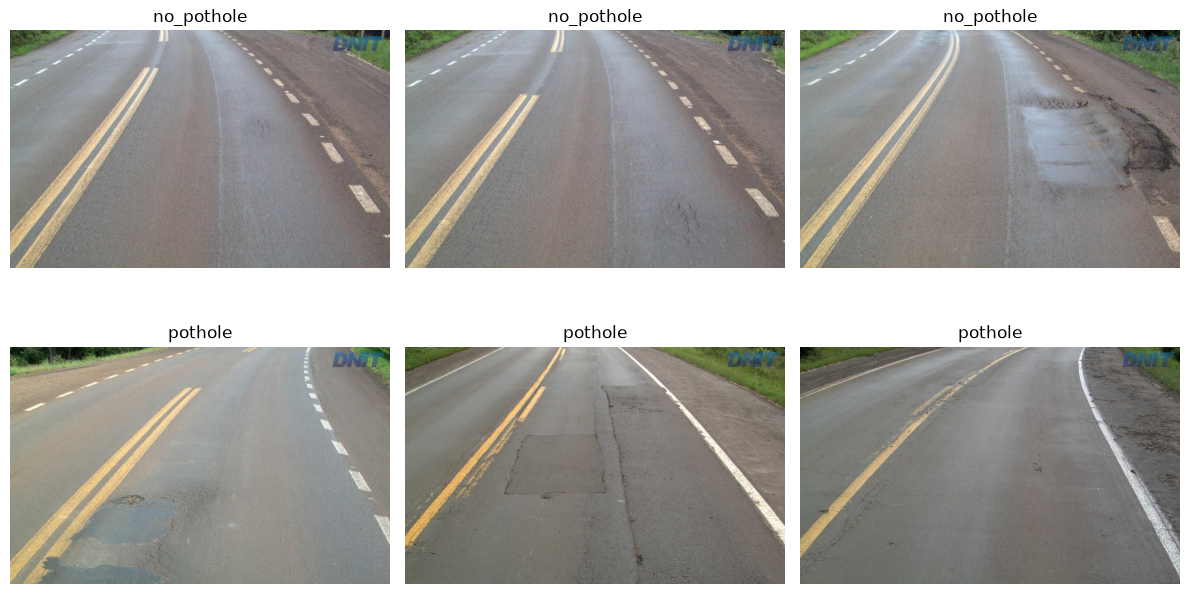

In [40]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7))

for row, class_name in enumerate(CLASSES):

    image_paths = sorted(
        (DATA_DIR / class_name).glob("*.jpg")
    )[:3]

    for col, image_path in enumerate(image_paths):

        image = Image.open(image_path).convert("RGB")

        axes[row, col].imshow(image)
        axes[row, col].set_title(class_name)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

## 5. Dataset Preparation and Preprocessing

The dataset preprocessing implementation is maintained in `src/dataset.py`.

It performs the following operations:

- Loads images and their corresponding labels.
- Resizes images to the required dimensions.
- Applies data augmentation to training images.
- Normalizes image pixel values.
- Divides the dataset into training, validation, and testing subsets.

The dataset is divided using stratified sampling:

- 70% Training
- 15% Validation
- 15% Testing

We reuse the existing implementation instead of duplicating the preprocessing logic.

In [45]:
# Add the src directory to Python's module search path

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from dataset import make_splits, CLASSES, eval_transform

train_ds, val_ds, test_ds = make_splits(DATA_DIR)

print("Training samples:", len(train_ds))
print("Validation samples:", len(val_ds))
print("Testing samples:", len(test_ds))

print("Total samples:", len(train_ds) + len(val_ds) + len(test_ds))

Training samples: 1564
Validation samples: 335
Testing samples: 336
Total samples: 2235


In [46]:
# Inspect one sample from the training dataset

image, label = train_ds[0]

print("Image tensor shape:", image.shape)
print("Image label:", label)
print("Class:", CLASSES[label])

Image tensor shape: torch.Size([3, 160, 160])
Image label: 0
Class: no_pothole


## 6. Model Architecture

The project uses a custom Residual Convolutional Neural Network (CNN).

The architecture consists of:

1. Initial convolutional layer.
2. Batch normalization and ReLU activation.
3. Multiple residual blocks.
4. Adaptive average pooling.
5. Fully connected classification layers.
6. Dropout for regularization.

Residual connections help information and gradients flow through deeper network layers.

The model is implemented in `src/model.py` and is trained from scratch without pretrained weights.

In [47]:
from model import PotholeCNN, load_checkpoint

model = PotholeCNN(num_classes=2)

print(model)

PotholeCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Sequential(
      (0): ResidualBlock(
        (conv1): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (shortcut): Identity()
        (activation): ReLU(inplace=True)
      )
      (1): ResidualBlock(
        (conv1): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stat

In [48]:
# Check the number of trainable parameters

total_params = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("Total trainable parameters:", total_params)

Total trainable parameters: 703714


In [49]:
# Test the model with a dummy input

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)

dummy_input = torch.randn(1, 3, 160, 160).to(device)

model.eval()

with torch.no_grad():
    output = model(dummy_input)

print("Input shape:", dummy_input.shape)
print("Output shape:", output.shape)
print("Output:", output)

Input shape: torch.Size([1, 3, 160, 160])
Output shape: torch.Size([1, 2])
Output: tensor([[0.1289, 0.1180]])


## 7. Model Training

The training pipeline is implemented in `src/train.py`.

The training process includes:

- Weighted Cross Entropy Loss to handle class imbalance.
- AdamW optimizer.
- ReduceLROnPlateau learning rate scheduler.
- Validation after every epoch.
- Early stopping to reduce overfitting.
- Saving the best-performing model checkpoint.

The model is trained using the training dataset and monitored using the validation dataset.

The test dataset is not used during training.

In [50]:
# Set this to True only if you want to train the model again.

RUN_TRAINING = False

CHECKPOINT_PATH = MODELS_DIR / "best_model.pt"

print("Existing checkpoint:", CHECKPOINT_PATH.exists())
print("Training enabled:", RUN_TRAINING)

Existing checkpoint: True
Training enabled: False


In [51]:
if RUN_TRAINING:

    # Back up the existing checkpoint before retraining
    if CHECKPOINT_PATH.exists():

        backup_path = MODELS_DIR / "best_model_before_notebook.pt"

        if not backup_path.exists():
            import shutil
            shutil.copy2(CHECKPOINT_PATH, backup_path)

            print("Previous checkpoint backed up to:", backup_path)

    command = [
        sys.executable,
        str(SRC_DIR / "train.py"),
        "--data-dir", str(DATA_DIR),
        "--epochs", "50",
        "--batch-size", "32",
        "--lr", "3e-4",
        "--patience", "10",
    ]

    subprocess.run(
        command,
        cwd=ROOT,
        check=True
    )

    print("Training completed!")

else:
    print("Training skipped. Using the existing trained model.")

Training skipped. Using the existing trained model.


## 8. Training Results

The training script stores the training history and learning curves in the results directory.

We visualize the loss and accuracy curves to understand the model's learning behaviour.

In [52]:
history_path = RESULTS_DIR / "history.json"

if history_path.exists():

    with open(history_path, "r") as file:
        history = json.load(file)

    print("Training history loaded successfully.")

else:
    print("Training history not found. Run the training section first.")

Training history loaded successfully.


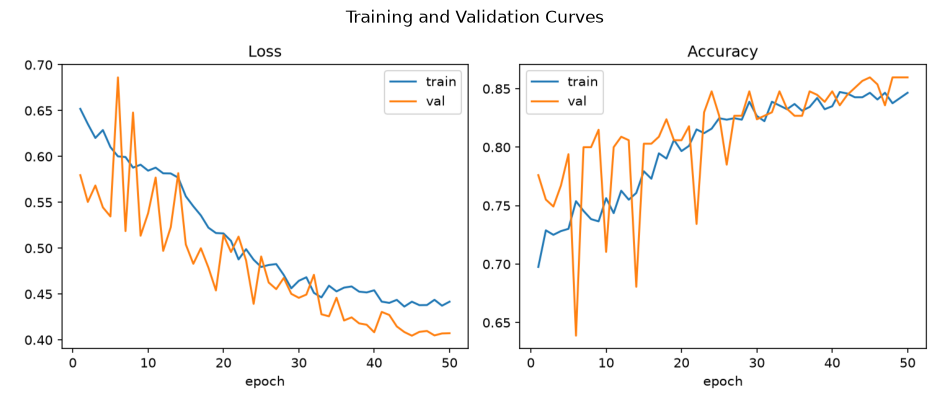

In [53]:
training_curves = RESULTS_DIR / "training_curves.png"

if training_curves.exists():

    image = Image.open(training_curves)

    plt.figure(figsize=(12, 6))
    plt.imshow(image)
    plt.axis("off")
    plt.title("Training and Validation Curves")
    plt.show()

else:
    print("Training curves not found.")

## 9. Model Evaluation

The trained model is evaluated on the held-out test dataset.

The evaluation implementation is maintained in `src/evaluate.py`.

The following metrics are calculated:

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC

A confusion matrix is also generated to visualize the classification performance.

The test dataset is kept separate from model training and validation.

In [55]:
assert CHECKPOINT_PATH.exists(), (
    "Model checkpoint not found. Train the model first or check your models folder."
)

command = [
    sys.executable,
    str(SRC_DIR / "evaluate.py"),
    "--data-dir", str(DATA_DIR),
    "--checkpoint", str(CHECKPOINT_PATH),
    "--batch-size", "32",
]

subprocess.run(
    command,
    cwd=ROOT,
    check=True
)

CompletedProcess(args=['D:\\RideSafe\\pothole-detection\\.venv\\Scripts\\python.exe', 'D:\\RideSafe\\pothole-detection\\src\\evaluate.py', '--data-dir', 'D:\\RideSafe\\pothole-detection\\data', '--checkpoint', 'D:\\RideSafe\\pothole-detection\\models\\best_model.pt', '--batch-size', '32'], returncode=0)

In [56]:
metrics_path = RESULTS_DIR / "metrics.json"

with open(metrics_path, "r") as file:
    metrics = json.load(file)

print("Test Evaluation Metrics\n")

for metric, value in metrics.items():
    print(f"{metric}: {value:.4f}" if isinstance(value, float) else f"{metric}: {value}")

Test Evaluation Metrics

n_test: 336
decision_threshold: 0.3008
accuracy: 0.8214
precision: 0.6344
recall: 0.6941
f1: 0.6629
roc_auc: 0.8424


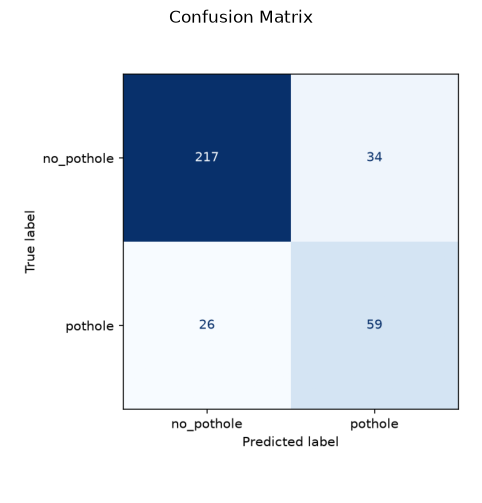

In [57]:
confusion_matrix_path = RESULTS_DIR / "confusion_matrix.png"

if confusion_matrix_path.exists():

    cm_image = Image.open(confusion_matrix_path)

    plt.figure(figsize=(6, 6))
    plt.imshow(cm_image)
    plt.axis("off")
    plt.title("Confusion Matrix")
    plt.show()

else:
    print("Confusion matrix not found.")

## 10. Single Image Prediction

The trained model can also classify an individual road image.

The prediction implementation is maintained in `src/predict.py`.

The image is preprocessed using the same evaluation transformations used during testing.

The model predicts whether the image contains a pothole or no pothole.

In [63]:
# Enter the path to an image you want to test

IMAGE_PATH = DATA_DIR / "pothole" / "883044_RS_290_290RS150131_15951.jpg"

print("Image exists:", IMAGE_PATH.exists())
print("Image path:", IMAGE_PATH)

Image exists: True
Image path: D:\RideSafe\pothole-detection\data\pothole\883044_RS_290_290RS150131_15951.jpg


In [64]:
assert IMAGE_PATH.exists(), "Please provide a valid image path."

command = [
    sys.executable,
    str(SRC_DIR / "predict.py"),
    str(IMAGE_PATH),
    "--checkpoint", str(CHECKPOINT_PATH),
]

subprocess.run(
    command,
    cwd=ROOT,
    check=True
)

CompletedProcess(args=['D:\\RideSafe\\pothole-detection\\.venv\\Scripts\\python.exe', 'D:\\RideSafe\\pothole-detection\\src\\predict.py', 'D:\\RideSafe\\pothole-detection\\data\\pothole\\883044_RS_290_290RS150131_15951.jpg', '--checkpoint', 'D:\\RideSafe\\pothole-detection\\models\\best_model.pt'], returncode=0)

## 11. Conclusion

RideSafe demonstrates the application of deep learning for road pothole detection.

A custom Residual CNN was developed and trained from scratch using PyTorch.

The project includes:

- Dataset exploration and preprocessing.
- Custom CNN architecture with residual connections.
- Model training with validation and early stopping.
- Performance evaluation using multiple classification metrics.
- Single-image pothole prediction.

The project provides a foundation for developing intelligent road monitoring and road safety applications.